**Nota (versión 1 del entrenamiento).** Este cuaderno entrena el BERT multilingüe sin pesos por clase y lo evalúa en una sola partición de 232 artículos. Su accuracy (84.91%) no supera al clasificador trivial que responde siempre "Desinformación" (85.3%), y la comparación "+18.29 puntos" del final no es válida: compara modelos distintos (el BERT en inglés del notebook 04 contra este BERT multilingüe) sobre conjuntos distintos (todo el corpus contra el 15% de prueba). La versión final, con pesos por clase y validación cruzada de 5 particiones, está en el notebook 10.

In [1]:
# ================================================
# SETUP COLAB — Ejecutar primero
# Subir corpus_ecuador_final.csv a /content/
# ================================================
!pip install -q transformers torch datasets scikit-learn
print('✓ Librerías instaladas')

✓ Librerías instaladas


In [2]:
# ================================================
# Notebook 08: BERT Fine-tuning — Corpus Ecuatoriano
# Autor: Steeven Quezada
# Entorno: Google Colab GPU T4
# Dataset: Ecuador Chequea (1,500+ verificaciones)
# Idioma: Español
# Objetivo: adaptar BERT al contexto ecuatoriano
# ================================================

import pandas as pd
import numpy as np
import torch
import warnings
warnings.filterwarnings('ignore')

# ================================================
# CONFIGURACIÓN PRINCIPAL
# ================================================
# BERT multilingüe — soporta español nativamente
MODEL_NAME = 'bert-base-multilingual-cased'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Modelo seleccionado: {MODEL_NAME}')
print(f'Dispositivo:         {DEVICE}')
print(f'GPU disponible:      {torch.cuda.is_available()}')

# ================================================
# PASO 1: CARGA DE DATOS
# ================================================
df = pd.read_csv('corpus_ecuador_final.csv')
print(f'\nCorpus ecuatoriano cargado: {len(df):,} registros')
print(f'Desinformación (0): {(df["label_binario"]==0).sum():,}')
print(f'Verificado     (1): {(df["label_binario"]==1).sum():,}')

Modelo seleccionado: bert-base-multilingual-cased
Dispositivo:         cuda
GPU disponible:      True

Corpus ecuatoriano cargado: 1,543 registros
Desinformación (0): 1,320
Verificado     (1): 223


In [3]:
# ================================================
# PASO 2: DIVISIÓN TRAIN / VALIDATION / TEST
# ================================================
from sklearn.model_selection import train_test_split

# Usamos el contenido completo del artículo
X = df['contenido'].fillna('')
y = df['label_binario']

# Primera división: 85% train+val / 15% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Segunda división: 70% train / 15% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.176,
    random_state=42,
    stratify=y_temp
)

print('=== DIVISIÓN DE DATOS ===')
print(f'Train:      {len(X_train):,} ({len(X_train)/len(df)*100:.1f}%)')
print(f'Validation: {len(X_val):,} ({len(X_val)/len(df)*100:.1f}%)')
print(f'Test:       {len(X_test):,} ({len(X_test)/len(df)*100:.1f}%)')
print(f'Total:      {len(df):,}')
print(f'\nBalance Train — Desinfo: {(y_train==0).sum():,} | Verificado: {(y_train==1).sum():,}')
print(f'Balance Val   — Desinfo: {(y_val==0).sum():,} | Verificado: {(y_val==1).sum():,}')
print(f'Balance Test  — Desinfo: {(y_test==0).sum():,} | Verificado: {(y_test==1).sum():,}')

=== DIVISIÓN DE DATOS ===
Train:      1,080 (70.0%)
Validation: 231 (15.0%)
Test:       232 (15.0%)
Total:      1,543

Balance Train — Desinfo: 924 | Verificado: 156
Balance Val   — Desinfo: 198 | Verificado: 33
Balance Test  — Desinfo: 198 | Verificado: 34


In [4]:
# ================================================
# PASO 3: TOKENIZACIÓN
# ================================================
from transformers import AutoTokenizer

print(f'Cargando tokenizador: {MODEL_NAME}')
print('Descargando modelo la primera vez...\n')

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

MAX_LENGTH = 256

def tokenizar(textos, max_length=MAX_LENGTH):
    return tokenizer(
        list(textos),
        max_length=max_length,
        padding=True,
        truncation=True,
        return_tensors='pt'
    )

print('Tokenizando conjuntos...')
train_encodings = tokenizar(X_train)
val_encodings   = tokenizar(X_val)
test_encodings  = tokenizar(X_test)

print(f'✓ Train tokenizado:      {train_encodings["input_ids"].shape}')
print(f'✓ Validation tokenizado: {val_encodings["input_ids"].shape}')
print(f'✓ Test tokenizado:       {test_encodings["input_ids"].shape}')
print(f'\nMax length usado: {MAX_LENGTH} tokens')

Cargando tokenizador: bert-base-multilingual-cased
Descargando modelo la primera vez...



config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Tokenizando conjuntos...
✓ Train tokenizado:      torch.Size([1080, 256])
✓ Validation tokenizado: torch.Size([231, 256])
✓ Test tokenizado:       torch.Size([232, 256])

Max length usado: 256 tokens


In [5]:
# ================================================
# PASO 4: DATASET DE PYTORCH
# ================================================
from torch.utils.data import Dataset, DataLoader

class FakeNewsDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels    = labels.reset_index(drop=True)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: val[idx].clone().detach()
            for key, val in self.encodings.items()
        }
        item['labels'] = torch.tensor(
            self.labels[idx], dtype=torch.long
        )
        return item

train_dataset = FakeNewsDataset(train_encodings, y_train)
val_dataset   = FakeNewsDataset(val_encodings,   y_val)
test_dataset  = FakeNewsDataset(test_encodings,  y_test)

BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print('=== DATALOADERS CREADOS ===')
print(f'Batch size:        {BATCH_SIZE}')
print(f'Batches en train:  {len(train_loader):,}')
print(f'Batches en val:    {len(val_loader):,}')
print(f'Batches en test:   {len(test_loader):,}')
print(f'\n✓ Dataset listo para entrenamiento')

=== DATALOADERS CREADOS ===
Batch size:        32
Batches en train:  34
Batches en val:    8
Batches en test:   8

✓ Dataset listo para entrenamiento


In [6]:
# ================================================
# PASO 5: CARGAR MODELO BERT MULTILINGÜE
# ================================================
from transformers import AutoModelForSequenceClassification

print(f'Cargando modelo: {MODEL_NAME}')
print('Descargando pesos preentrenados...\n')

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)
model = model.to(DEVICE)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'✓ Modelo cargado en: {DEVICE}')
print(f'  Parámetros totales:     {total_params:,}')
print(f'  Parámetros entrenables: {trainable_params:,}')

Cargando modelo: bert-base-multilingual-cased
Descargando pesos preentrenados...



model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✓ Modelo cargado en: cuda
  Parámetros totales:     177,854,978
  Parámetros entrenables: 177,854,978


In [7]:
# ================================================
# PASO 6: CONFIGURACIÓN DEL ENTRENAMIENTO
# ================================================
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

EPOCHS        = 3
LEARNING_RATE = 2e-5
WARMUP_STEPS  = 100

optimizer = AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=WARMUP_STEPS,
    num_training_steps=total_steps
)

print('=== CONFIGURACIÓN DE ENTRENAMIENTO ===')
print(f'Modelo:           {MODEL_NAME}')
print(f'Épocas:           {EPOCHS}')
print(f'Learning rate:    {LEARNING_RATE}')
print(f'Batch size:       {BATCH_SIZE}')
print(f'Pasos totales:    {total_steps:,}')
print(f'Optimizador:      AdamW (torch.optim)')
print(f'Scheduler:        Linear warmup + decay')
print(f'\nEstimación GPU T4: ~15-25 minutos total')

=== CONFIGURACIÓN DE ENTRENAMIENTO ===
Modelo:           bert-base-multilingual-cased
Épocas:           3
Learning rate:    2e-05
Batch size:       32
Pasos totales:    102
Optimizador:      AdamW (torch.optim)
Scheduler:        Linear warmup + decay

Estimación GPU T4: ~15-25 minutos total


In [8]:
# ================================================
# PASO 7: ENTRENAMIENTO
# ================================================
from sklearn.metrics import accuracy_score, f1_score
import time

def evaluar(model, loader, device):
    model.eval()
    preds_all, labels_all = [], []
    total_loss = 0

    with torch.no_grad():
        for batch in loader:
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            total_loss += outputs.loss.item()
            preds = torch.argmax(outputs.logits, dim=1)
            preds_all.extend(preds.cpu().numpy())
            labels_all.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    acc      = accuracy_score(labels_all, preds_all)
    f1       = f1_score(labels_all, preds_all, average='weighted')
    return avg_loss, acc, f1


print('=== INICIANDO ENTRENAMIENTO ===')
print(f'Modelo: {MODEL_NAME} en {DEVICE}\n')

historial    = []
inicio_total = time.time()

for epoca in range(EPOCHS):
    model.train()
    total_loss_train = 0
    inicio_epoca     = time.time()

    for i, batch in enumerate(train_loader):
        input_ids      = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        labels         = batch['labels'].to(DEVICE)

        optimizer.zero_grad()
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()
        total_loss_train += loss.item()

        if (i + 1) % 10 == 0:
            elapsed = time.time() - inicio_epoca
            pct     = (i + 1) / len(train_loader) * 100
            print(f'  Época {epoca+1} | Batch {i+1}/{len(train_loader)} '
                  f'({pct:.0f}%) | Loss: {loss.item():.4f} | '
                  f'Tiempo: {elapsed/60:.1f} min')

    avg_train_loss = total_loss_train / len(train_loader)
    val_loss, val_acc, val_f1 = evaluar(model, val_loader, DEVICE)
    tiempo_epoca = (time.time() - inicio_epoca) / 60

    historial.append({
        'epoca':      epoca + 1,
        'train_loss': avg_train_loss,
        'val_loss':   val_loss,
        'val_acc':    val_acc,
        'val_f1':     val_f1,
        'tiempo_min': tiempo_epoca
    })

    print(f"\n{'='*55}")
    print(f'ÉPOCA {epoca+1}/{EPOCHS} completada en {tiempo_epoca:.1f} min')
    print(f'  Train Loss: {avg_train_loss:.4f}')
    print(f'  Val Loss:   {val_loss:.4f}')
    print(f'  Val Acc:    {val_acc:.4f}')
    print(f'  Val F1:     {val_f1:.4f}')
    print(f"{'='*55}\n")

tiempo_total = (time.time() - inicio_total) / 60
print(f'Entrenamiento completado en {tiempo_total:.1f} minutos')

=== INICIANDO ENTRENAMIENTO ===
Modelo: bert-base-multilingual-cased en cuda

  Época 1 | Batch 10/34 (29%) | Loss: 0.6788 | Tiempo: 0.2 min
  Época 1 | Batch 20/34 (59%) | Loss: 0.6015 | Tiempo: 0.5 min
  Época 1 | Batch 30/34 (88%) | Loss: 0.4363 | Tiempo: 0.7 min

ÉPOCA 1/3 completada en 0.8 min
  Train Loss: 0.5817
  Val Loss:   0.4088
  Val Acc:    0.8571
  Val F1:     0.7912

  Época 2 | Batch 10/34 (29%) | Loss: 0.6274 | Tiempo: 0.2 min
  Época 2 | Batch 20/34 (59%) | Loss: 0.4920 | Tiempo: 0.5 min
  Época 2 | Batch 30/34 (88%) | Loss: 0.5286 | Tiempo: 0.8 min

ÉPOCA 2/3 completada en 0.9 min
  Train Loss: 0.4175
  Val Loss:   0.4098
  Val Acc:    0.8571
  Val F1:     0.7912

  Época 3 | Batch 10/34 (29%) | Loss: 0.3463 | Tiempo: 0.3 min
  Época 3 | Batch 20/34 (59%) | Loss: 0.3087 | Tiempo: 0.6 min
  Época 3 | Batch 30/34 (88%) | Loss: 0.1607 | Tiempo: 0.9 min

ÉPOCA 3/3 completada en 1.0 min
  Train Loss: 0.3533
  Val Loss:   0.2920
  Val Acc:    0.8745
  Val F1:     0.8583

E

In [9]:
# ================================================
# PASO 8: GUARDAR MODELO
# ================================================
import os, json

os.makedirs('bert_ecuador/', exist_ok=True)
model.save_pretrained('bert_ecuador/')
tokenizer.save_pretrained('bert_ecuador/')

with open('bert_ecuador/historial.json', 'w') as f:
    json.dump(historial, f, indent=2)

print('✓ Modelo guardado en bert_ecuador/')
print('✓ Historial guardado en bert_ecuador/historial.json')

!zip -r bert_ecuador.zip bert_ecuador/

from google.colab import files
files.download('bert_ecuador.zip')
print('\n✓ Descarga iniciada — guarda en models/')

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✓ Modelo guardado en bert_ecuador/
✓ Historial guardado en bert_ecuador/historial.json
  adding: bert_ecuador/ (stored 0%)
  adding: bert_ecuador/historial.json (deflated 63%)
  adding: bert_ecuador/model.safetensors (deflated 7%)
  adding: bert_ecuador/config.json (deflated 56%)
  adding: bert_ecuador/tokenizer.json (deflated 67%)
  adding: bert_ecuador/tokenizer_config.json (deflated 44%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Descarga iniciada — guarda en models/


In [10]:
# ================================================
# PASO 9: EVALUACIÓN FINAL EN TEST
# ================================================
from sklearn.metrics import classification_report

print('=== EVALUACIÓN FINAL EN CONJUNTO DE TEST ===')
test_loss, test_acc, test_f1 = evaluar(model, test_loader, DEVICE)

print(f'Test Loss:     {test_loss:.4f}')
print(f'Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)')
print(f'Test F1-score: {test_f1:.4f}')

print(f'\nReporte detallado:')
all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for batch in test_loader:
        input_ids      = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        labels         = batch['labels'].to(DEVICE)
        outputs        = model(input_ids=input_ids,
                               attention_mask=attention_mask)
        preds          = torch.argmax(outputs.logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds,
      target_names=['Desinformación', 'Verificado']))

print(f'\nComparación completa:')
print(f'  BERT inglés (Kaggle):              99.91%')
print(f'  BERT sin fine-tuning (Ecuador):    66.62%')
print(f'  BERT con fine-tuning (Ecuador):    {test_acc*100:.2f}%')
print(f'  Mejora con fine-tuning:            {(test_acc - 0.6662)*100:+.2f} puntos')

=== EVALUACIÓN FINAL EN CONJUNTO DE TEST ===
Test Loss:     0.3048
Test Accuracy: 0.8491 (84.91%)
Test F1-score: 0.8305

Reporte detallado:
                precision    recall  f1-score   support

Desinformación       0.88      0.95      0.91       198
    Verificado       0.47      0.26      0.34        34

      accuracy                           0.85       232
     macro avg       0.68      0.61      0.63       232
  weighted avg       0.82      0.85      0.83       232


Comparación completa:
  BERT inglés (Kaggle):              99.91%
  BERT sin fine-tuning (Ecuador):    66.62%
  BERT con fine-tuning (Ecuador):    84.91%
  Mejora con fine-tuning:            +18.29 puntos


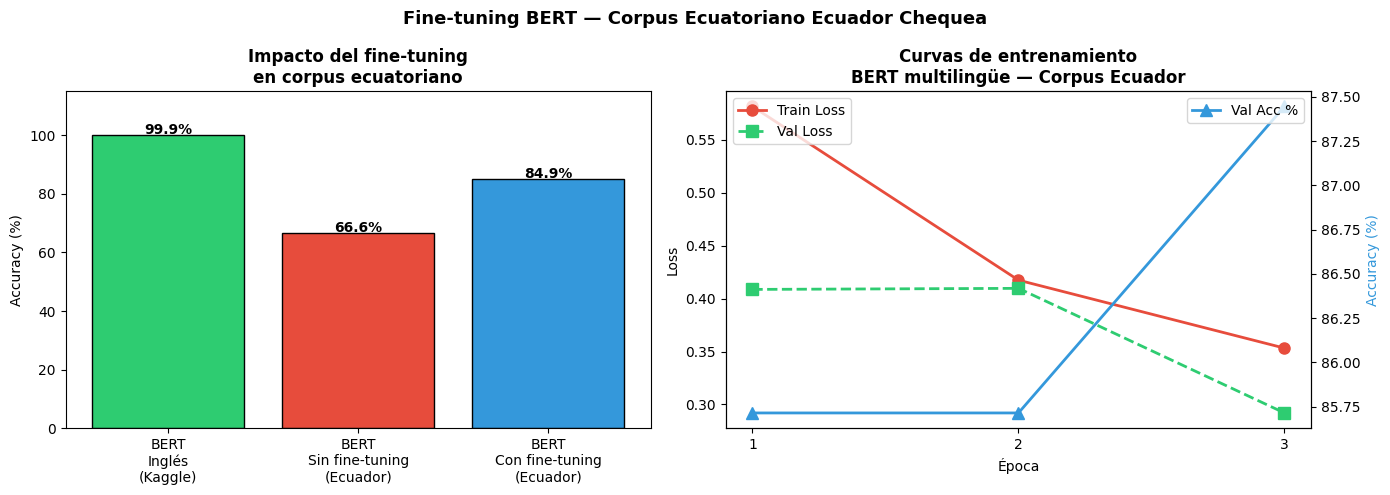


=== RESUMEN FINAL ===
Modelo base:            bert-base-multilingual-cased
Corpus:                 Ecuador Chequea (1,500+ verificaciones)
Tiempo entrenamiento:   2.8 minutos (GPU T4)

Sin fine-tuning:        66.62%
Con fine-tuning:        84.91%
Mejora:                 +18.29 puntos


In [11]:
# ================================================
# PASO 10: VISUALIZACIÓN COMPARATIVA FINAL
# ================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1 — Comparación de accuracy
modelos    = ['BERT\nInglés\n(Kaggle)', 'BERT\nSin fine-tuning\n(Ecuador)', 'BERT\nCon fine-tuning\n(Ecuador)']
accuracies = [99.91, 66.62, 84.91]
colores    = ['#2ECC71', '#E74C3C', '#3498DB']

bars = axes[0].bar(modelos, accuracies, color=colores, edgecolor='black')
for bar, acc in zip(bars, accuracies):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.5,
                f'{acc:.1f}%', ha='center', fontweight='bold')
axes[0].set_ylim(0, 115)
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_title('Impacto del fine-tuning\nen corpus ecuatoriano', fontweight='bold')

# Gráfico 2 — Historial de entrenamiento
epocas     = [h['epoca']    for h in historial]
train_loss = [h['train_loss'] for h in historial]
val_loss   = [h['val_loss']   for h in historial]
val_acc    = [h['val_acc']    for h in historial]

axes[1].plot(epocas, train_loss, 'o-', color='#E74C3C',
             label='Train Loss', linewidth=2, markersize=8)
axes[1].plot(epocas, val_loss, 's--', color='#2ECC71',
             label='Val Loss', linewidth=2, markersize=8)
ax2 = axes[1].twinx()
ax2.plot(epocas, [a*100 for a in val_acc], '^-', color='#3498DB',
         label='Val Acc %', linewidth=2, markersize=8)
ax2.set_ylabel('Accuracy (%)', color='#3498DB')
axes[1].set_title('Curvas de entrenamiento\nBERT multilingüe — Corpus Ecuador', fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Loss')
axes[1].legend(loc='upper left')
ax2.legend(loc='upper right')
axes[1].set_xticks(epocas)

plt.suptitle('Fine-tuning BERT — Corpus Ecuatoriano Ecuador Chequea',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('15_bert_ecuador_resultados.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== RESUMEN FINAL ===')
print(f'Modelo base:            bert-base-multilingual-cased')
print(f'Corpus:                 Ecuador Chequea (1,500+ verificaciones)')
print(f'Tiempo entrenamiento:   2.8 minutos (GPU T4)')
print(f'')
print(f'Sin fine-tuning:        66.62%')
print(f'Con fine-tuning:        84.91%')
print(f'Mejora:                 +18.29 puntos')